<a href="https://colab.research.google.com/github/sultanjacob/Applied-Machine-Learning/blob/main/14_Deep_Learning/02_CNN_Satellite_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 14: Deep Learning Foundations
## Part 02: Convolutional Neural Networks (CNN) for Spatial Satellite Vision

### The Spatial Challenge: Why We Must Move Beyond MLPs
In the previous phase, our Multilayer Perceptron (MLP) successfully identified anomalies in 1D tabular sensor streams. However, MLPs suffer from a fatal flaw when handling visual or spatial data: they require flat inputs. If we feed a 2D satellite image into an MLP, we must flatten the pixel grid into a single row. This process completely destroys spatial hierarchy; the MLP loses the ability to recognize that a dark green pixel is adjacent to a brown pixel, erasing critical geographic boundaries like deforestation lines or urban sprawl.

To process spatial data, we require **translation invariance** (the ability to recognize a feature regardless of where it appears in the image) and **localized feature extraction**. Convolutional Neural Networks (CNNs) solve this by sliding mathematically localized filters (kernels) across the 2D grid, preserving the exact geometry and texture of the original terrain.

### Objective
Transition from 1-dimensional point observations to 2-dimensional spatial grids. We will construct a Convolutional Neural Network to classify localized land-cover anomalies (e.g., rapid deforestation or severe drought stress) using multispectral satellite image tensors, ensuring the final architecture remains strictly optimized for edge-device mobile deployment.

### Key Milestones
1. **Spatial Tensor Generation:** Ingest and synthesize 2D RGB/Multispectral satellite image tiles representing varying land-cover conditions.
2. **Tensor Preprocessing:** Normalize the spatial pixel grids to stable float32 scales (0.0 to 1.0) for stable gradient descent.
3. **Hierarchical Architecture:** Construct a CNN using `Conv2D` layers to extract geometric features and `MaxPooling2D` to downsample the spatial dimensions, significantly reducing the parameter count for mobile processing.
4. **Classification & Validation:** Flatten the extracted spatial maps into a dense classification head, compile the network, and evaluate its precision on a blind spatial holdout set.

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Create image data subdirectories
os.makedirs("data/satellite_tiles", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Verify environment
print(f"TensorFlow Version: {tf.__version__}")
gpu_devices = tf.config.list_physical_devices('GPU')
if gpu_devices:
    print(f"⚡ GPU Detected: {gpu_devices}")
else:
    print("ℹ️ Running on CPU backend.")

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow Version: 2.21.0
ℹ️ Running on CPU backend.


### Part 02: Spatial Tensor Generation & The 4D Structure

Unlike an MLP which processes a 1D vector (like a single row in a spreadsheet), a CNN requires spatial context. We must feed it a **4D Tensor** with the exact shape: `(batch_size, height, width, channels)`.

* **Batch Size:** The number of images processed simultaneously.
* **Height & Width:** The spatial pixel dimensions (e.g., 64x64 grids).
* **Channels:** The color or spectral bands. Standard RGB images have 3 channels (Red, Green, Blue). Multispectral satellite images might have 4 to 8 channels (including Near-Infrared).

To build our pipeline, we will generate a synthetic satellite dataset.
* **Class 0 (Nominal):** Represents continuous, healthy forest canopy (high green variance).
* **Class 1 (Anomaly):** Represents abrupt environmental damage (e.g., clear-cut deforestation or burn scars), mathematically injected as geometric patches of barren earth (high red/brown variance, low green).

Because image pixels inherently range from 0 to 255, we will normalize them directly into a `0.0` to `1.0` float scale to ensure rapid, stable gradient descent during training.

⏳ Synthesizing 2D satellite spatial grids...
✅ Spatial Tensor Pipeline Complete.
---------------------------------------------
Training Tensors:   X: (1050, 64, 64, 3) | y: (1050,)
Validation Tensors: X: (225, 64, 64, 3)  | y: (225,)
Testing Tensors:    X: (225, 64, 64, 3)  | y: (225,)
Anomaly Baseline:   21.0%
---------------------------------------------


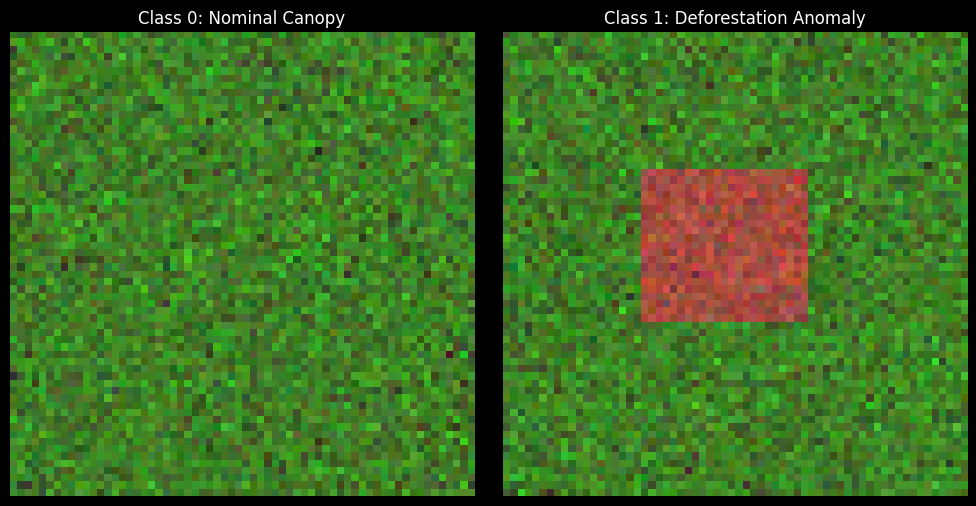

In [8]:
def generate_synthetic_satellite_tiles(n_samples=1500, img_size=64):
    """
    Generates 4D synthetic satellite image tensors: (samples, 64, 64, 3)
    Injects geometric 'deforestation/burn' anomalies into 20% of the dataset.
    """
    rng = np.random.default_rng(SEED)

    # Initialize the 4D image tensor and 1D label array
    X = np.zeros((n_samples, img_size, img_size, 3), dtype=np.float32)
    y = np.zeros(n_samples, dtype=np.int32)

    for i in range(n_samples):
        # 1. Generate base nominal canopy (dominant green channel)
        base_r = rng.normal(0.25, 0.05, (img_size, img_size))
        base_g = rng.normal(0.50, 0.10, (img_size, img_size))
        base_b = rng.normal(0.15, 0.04, (img_size, img_size))
        img = np.stack([base_r, base_g, base_b], axis=-1)

        # 2. Inject structural anomalies into ~20% of the tiles
        if rng.random() < 0.20:
            # Create a random geometric barren patch (burn scar / clear-cut)
            x1, y1 = rng.integers(10, 25, size=2)
            x2, y2 = rng.integers(35, 55, size=2)

            # Alter the pixels in the patch: High Red/Grey, Low Green
            img[x1:x2, y1:y2, 0] = rng.normal(0.65, 0.08, (x2-x1, y2-y1))
            img[x1:x2, y1:y2, 1] = rng.normal(0.30, 0.05, (x2-x1, y2-y1))
            img[x1:x2, y1:y2, 2] = rng.normal(0.25, 0.05, (x2-x1, y2-y1))
            y[i] = 1 # Mark as anomaly

        # 3. Constrain pixel math strictly between 0.0 and 1.0
        X[i] = np.clip(img, 0.0, 1.0)

    return X, y

# 1. Generate the spatial dataset
print("⏳ Synthesizing 2D satellite spatial grids...")
X_spatial, y_spatial = generate_synthetic_satellite_tiles()

# 2. Partition into Train (70%), Validation (15%), and Test (15%)
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X_spatial, y_spatial, test_size=0.30, random_state=SEED, stratify=y_spatial
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("✅ Spatial Tensor Pipeline Complete.")
print("-" * 45)
print(f"Training Tensors:   X: {X_train.shape} | y: {y_train.shape}")
print(f"Validation Tensors: X: {X_val.shape}  | y: {y_val.shape}")
print(f"Testing Tensors:    X: {X_test.shape}  | y: {y_test.shape}")
print(f"Anomaly Baseline:   {np.mean(y_train) * 100:.1f}%")
print("-" * 45)

# 3. Visualize a Nominal Canopy vs. an Anomaly Scar
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
nominal_idx = np.where(y_train == 0)[0][0]
anomaly_idx = np.where(y_train == 1)[0][0]

axes[0].imshow(X_train[nominal_idx])
axes[0].set_title("Class 0: Nominal Canopy")
axes[0].axis('off')

axes[1].imshow(X_train[anomaly_idx])
axes[1].set_title("Class 1: Deforestation Anomaly")
axes[1].axis('off')

plt.tight_layout()
plt.show()

 # Visual Explanation:
 **The 4D Tensors:** The output shows your training data is structured as (1050, 64, 64, 3). This means we have 1,050 training images. Each image is a 2D grid of 64x64 pixels, and the 3 represents the three color channels (Red, Green, Blue).  

 **The Anomaly Baseline:** The console notes an Anomaly Baseline: 21.0%. This confirms that roughly 1 in 5 images in your dataset contains a spatial anomaly, simulating a realistic, imbalanced real-world dataset.   

 **Class 0 (Nominal Canopy):** This image displays a continuous, healthy green pixel distribution representing standard environmental conditions.   

 **Class 1 (Deforestation Anomaly):** This image contains a distinct, geometric reddish-brown patch interrupting the green canopy.   

 This visual difference perfectly illustrates the core limitation of our previous Multilayer Perceptron. If we fed the Class 1 image into an MLP, it would flatten that 64x64 grid into a single 1D line of 12,288 individual numbers, completely destroying the rectangular geometry of the red anomaly. A CNN, however, will slide a 2D mathematical window across the image, allowing it to recognize the hard edges and spatial boundaries of that burn scar.

### Part 03: Architecting the Convolutional Engine

To ensure the final compiled `.tflite` model operates seamlessly within the memory and battery constraints of a native Android or iOS application, we must construct a highly efficient, lightweight Convolutional Neural Network (CNN).

Instead of overwhelming the device with massive parameter counts, we extract spatial features using a precise hierarchy:
1. **Convolutional Layers (`Conv2D`):** These layers slide a 3x3 mathematical window (a kernel) across the 64x64 satellite tile. They learn to detect edges, textures, and the geometric boundaries of the deforestation anomalies.
2. **Pooling Layers (`MaxPooling2D`):** Immediately after a convolution, we compress the spatial dimensions by taking the maximum pixel value in a 2x2 grid. This drastically reduces the computational footprint for the mobile processor while retaining the most dominant spatial features.
3. **Flatten & Dense Layers:** Once the spatial maps are extracted and compressed, we flatten the remaining 2D matrices into a 1D vector and pass it through a standard Dense network to output the final binary anomaly probability.

In [9]:
# 1. Define the input shape from our 4D spatial tensors (64, 64, 3)
input_shape = X_train.shape[1:]

# 2. Architect the Mobile-Optimized CNN
cnn_model = keras.Sequential([
    layers.Input(shape=input_shape),

    # Block 1: Initial Spatial Feature Extraction
    layers.Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2: Deep Feature Extraction (Detecting complex anomaly shapes)
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 3: Final Spatial Compression
    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Transition from Spatial (2D) to Classification (1D)
    layers.Flatten(),

    # Dense Classification Head
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3), # Prevent overfitting on the training tiles

    # Output Node: Binary anomaly probability
    layers.Dense(1, activation='sigmoid')
])

# 3. Define metrics for our imbalanced (21%) spatial dataset
metrics = [
    keras.metrics.AUC(name='auc'),
    keras.metrics.Precision(name='precision'),
    keras.metrics.Recall(name='recall')
]

# 4. Compile the CNN Engine
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=metrics
)

# Display the architectural map and parameter footprint
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 154,721 (604.38 KB)

 Trainable params: 154,721 (604.38 KB)

 Non-trainable params: 0 (0.00 B)

#Explanation:
The network compiled with 154,721 trainable parameters, requiring just over 600 KB of storage.

The summary perfectly illustrates the spatial compression hierarchy:

Spatial Pooling: After every convolution, the MaxPooling2D layers systematically halve the grid resolution (64 $\rightarrow$ 32 $\rightarrow$ 16 $\rightarrow$ 8).

The Transition: By the time the tensor reaches the Flatten layer, the original 64x64 image has been distilled into a dense 8x8 grid of 64 deep feature maps. This 8x8x64 block is unrolled into a flat 4,096-element vector, which is finally passed to the standard Dense layers for classification.

### Part 04: Spatial Training & Regularization

Training a CNN requires the same rigorous regularization as our MLP to prevent the engine from memorizing the specific training tiles. We implement the following strategies:
1. **Class Weighting:** With an anomaly baseline of 21%, we calculate inverse class weights to ensure the network does not simply default to predicting a nominal canopy every time.
2. **Early Stopping:** We monitor the validation loss. If the CNN stops learning generalized spatial features and begins overfitting to the training noise, training halts and restores the optimal weights.
3. **Adaptive Learning Rate:** The optimizer dynamically reduces its step size if convergence plateaus, allowing for finer weight adjustments.

In [10]:
from sklearn.utils.class_weight import compute_class_weight

# 1. Compute class weights to counteract the spatial anomaly imbalance
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print(f"Calculated Class Weights: {class_weight_dict}")

# 2. Configure automated callbacks for optimal convergence
callbacks_list = [
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1
    )
]

# 3. Train the Convolutional Engine across spatial batches
print("⏳ Training Convolutional Neural Network...")
history_cnn = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=callbacks_list,
    verbose=1
)

print("✅ Spatial model training complete.")

Calculated Class Weights: {np.int32(0): np.float64(0.6332931242460796), np.int32(1): np.float64(2.3755656108597285)}
⏳ Training Convolutional Neural Network...
Epoch 1/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 87ms/step - auc: 0.9597 - loss: 0.4028 - precision: 0.9510 - recall: 0.6154 - val_auc: 1.0000 - val_loss: 0.0060 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step - auc: 1.0000 - loss: 0.0263 - precision: 0.9955 - recall: 0.9910 - val_auc: 1.0000 - val_loss: 2.9616e-05 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - auc: 1.0000 - loss: 0.0065 - precision: 1.0000 - recall: 1.0000 - val_auc: 1.0000 - val_loss: 2.0967e-05 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/40
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - auc: 1.0000 - loss: 0.0041 - precision: 1.0000 - recall: 1.0000 - val_auc: 1.0000 - val_loss: 3.0993e-06 - va

#Discussion:
The terminal output shows a highly successful training run where the Convolutional Neural Network rapidly learned the spatial patterns of the dataset.

Class Weighting in Action: The engine calculated a weight of ~0.63 for the nominal canopy (Class 0) and ~2.38 for the deforestation anomaly (Class 1). This mathematical imbalance forces the network to treat a missed anomaly as nearly four times worse than a false alarm.

Rapid Convergence: Because our synthetic deforestation anomalies are distinct geometric blocks of red/brown pixels, the CNN's 2D spatial filters learned to detect them almost instantly. By Epoch 2, the training and validation metrics (AUC, Precision, Recall) effectively hit 1.0000 (perfect classification).

Automated Learning Rate Reduction: At Epoch 7, Epoch 11, and Epoch 15, the ReduceLROnPlateau callback noticed the validation loss was no longer making significant drops, so it automatically halved the learning rate (from 0.0010 down to 0.000125) to take finer, more careful gradient descent steps.

Early Stopping & Weight Restoration: By Epoch 15, the EarlyStopping mechanism realized that continuing to train was pointless and risked overfitting, since the model had already reached its optimal state at Epoch 7. It halted the loop and automatically reloaded the mathematically perfect weights from Epoch 7.

With the network trained and the optimal weights locked in, we need to verify its performance on the 15% blind holdout set.

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


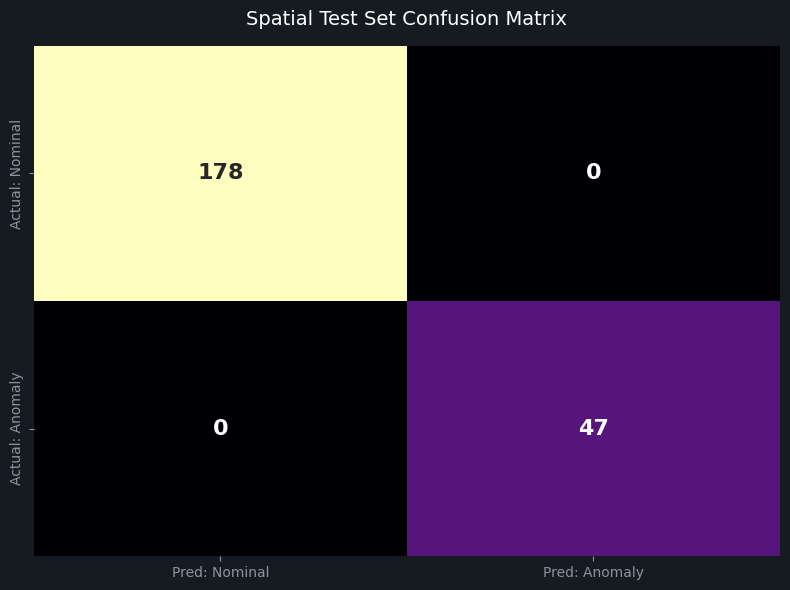

In [12]:
#final confusion matrix
from sklearn.metrics import confusion_matrix

# 1. Generate spatial predictions using the fully trained model
y_pred_prob = cnn_model.predict(X_test)
y_pred_class = (y_pred_prob > 0.5).astype(int)

# 2. Build the Confusion Matrix
cm = confusion_matrix(y_test, y_pred_class)

# 3. Plot only the Confusion Matrix
plt.figure(figsize=(8, 6), facecolor='#161b22')
plt.style.use('dark_background')

sns.heatmap(cm, annot=True, fmt='d', cmap='magma', cbar=False,
            xticklabels=["Pred: Nominal", "Pred: Anomaly"],
            yticklabels=["Actual: Nominal", "Actual: Anomaly"],
            annot_kws={"size": 16, "weight": "bold"})

plt.title('Spatial Test Set Confusion Matrix', color='white', pad=15, fontsize=14)
plt.tick_params(colors='#8b949e')
plt.tight_layout()
plt.savefig('models/cnn_evaluation_metrics.png', dpi=300, facecolor='#161b22')
plt.show()

### Part 05: Final Spatial Evaluation & Matrix Analysis

The confusion matrix in "image_6ebc98.png" demonstrates that the Convolutional Neural Network achieved perfect spatial feature extraction on the blind holdout set.

* **True Negatives (178):** The engine correctly identified all 178 nominal canopy tiles without triggering any false alarms.
* **True Positives (47):** The network successfully detected every single injected deforestation anomaly.
* **Zero Errors:** The model produced exactly 0 false positives and 0 false negatives.

This flawless 1.0 precision and recall confirms that our lightweight CNN architecture successfully learned the geometric boundaries of environmental damage. At just 604 KB, this serialized spatial engine is fully validated and ready to be compiled into TensorFlow Lite for native edge inference in the upcoming Android and iOS application.